# Member 4 — Support Vector Machine Analysis (revised)

**Project:** Predicting Online Purchase Intention from Browsing Behaviour  
**Member 4:** Yao Haotian (G2603151K)  
**Course:** MH6805 Machine Learning in Finance

## 1. Design and reproducibility

- Use the supplied fixed train/test split unchanged. `Revenue=True` is the positive class.
- Keep the original numeric standardization, categorical one-hot encoding,
  balanced SVM class weights, Linear/RBF parameter grids and seed 6805.
- Select parameters and kernels by **training-only, non-nested, stratified five-fold CV AP**.
  Here AP means `average_precision_score`, not trapezoidal area under a PR curve.
- Exclude `PageValues` in the main analysis; retain its inclusion as a sensitivity experiment.
- With selected parameters fixed, select a native-margin threshold maximizing training OOF F1.
  Those OOF predictions reuse the data used for parameter selection; their F1 is a development
  criterion, **not an unbiased nested-CV performance estimate**.
- Preserve five-fold sigmoid calibration with `ensemble=True`. Calibrated probabilities belong
  to an ensemble of fold models; they are distinct from the full-training model's native margins.
- Freeze all choices before computing fixed-test predictions. Prespecified probability cutoffs
  are descriptive scenarios, not candidates for selecting a cutoff using test F1.

The fixed test results have been inspected in earlier work. Keeping them outside fitting avoids
computational leakage, but rerunning this notebook does not make this a newly unseen test set.
CV SD below follows scikit-learn's population SD across folds (`ddof=0`); it is not a confidence interval.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import contextmanager
import hashlib
import importlib.metadata
import json
import os
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from joblib import parallel_config
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, log_loss,
    matthews_corrcoef, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

SEED = 6805
N_JOBS = min(4, os.cpu_count() or 1)  # Parallel fits; reduce to 1 if memory is limited.
DATA_DIR_OVERRIDE = None  # Optional: Path('your_data_folder'); do not edit model settings.
STRICT_REFERENCE_HASH = True  # The supplied, unchanged group CSV files are the reference.
PROBABILITY_SCENARIOS = (0.20, 0.30, 0.40, 0.50, 0.60)

CATEGORICAL = [
    'Month', 'OperatingSystems', 'Browser', 'Region',
    'TrafficType', 'VisitorType', 'Weekend',
]
NUMERIC_ALL = [
    'Administrative', 'Administrative_Duration', 'Informational',
    'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
    'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay',
]
PARAMETER_GRIDS = {
    'Linear': {'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1.0, 10.0]},
    'RBF': {
        'svc__kernel': ['rbf'], 'svc__C': [0.1, 1.0, 10.0, 100.0],
        'svc__gamma': ['scale', 0.001, 0.01, 0.1],
    },
}
REFERENCE_SHA256 = {
    'online_shoppers_train_fixed.csv':
        'f22e619801403164cbf67f878db6f7a44a0ae1490aa1988452609a934bc2ed85',
    'online_shoppers_test_fixed.csv':
        '4991664b2bbff1a2c20b64dcc8da1c8e594509be63eb1c72617ba8855bc03519',
}

RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
OUTPUT_DIR = Path('results') / 'member4_svm' / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
started_at = time.perf_counter()
stages = []
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
pd.set_option('display.max_columns', 20)

def write_json(name, value):
    (OUTPUT_DIR / name).write_text(
        json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8'
    )

def save_table(frame, name):
    frame.to_csv(OUTPUT_DIR / name, index=False, encoding='utf-8')

def save_figure(fig, name, width=1050):
    fig.tight_layout()
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=170, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(Image(filename=str(path), width=width))

@contextmanager
def stage(name):
    item = {'stage': name, 'status': 'running'}
    stages.append(item)
    write_json('run_status.json', {'status': 'running', 'stages': stages})
    tick = time.perf_counter()
    print(f'START {name}', flush=True)
    try:
        # SVC releases the GIL. Threads avoid Windows process/memmap cleanup issues.
        with parallel_config(backend='threading'):
            yield
    except Exception as exc:
        item.update(status='failed', error_type=type(exc).__name__)
        write_json('run_status.json', {'status': 'failed', 'stages': stages})
        raise
    else:
        item.update(status='complete', seconds=round(time.perf_counter() - tick, 3))
        write_json('run_status.json', {'status': 'running', 'stages': stages})
        print(f"DONE  {name} ({item['seconds']:.1f}s)", flush=True)

versions = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'joblib']:
    versions[package] = importlib.metadata.version(package)
write_json('environment.json', versions)
print('Library versions:', json.dumps(versions))
print('Output directory:', OUTPUT_DIR.as_posix())

Library versions: {"python": "3.13.15", "numpy": "2.3.5", "pandas": "2.2.3", "scipy": "1.17.0", "scikit-learn": "1.6.1", "matplotlib": "3.10.8", "joblib": "1.5.3"}
Output directory: results/member4_svm/20261024T141317_282061Z


In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def locate_data_pair():
    names = list(REFERENCE_SHA256)
    if DATA_DIR_OVERRIDE is not None:
        directories = [Path(DATA_DIR_OVERRIDE).expanduser().resolve()]
    else:
        here = Path.cwd().resolve()
        directories = [here / 'data', here / 'ML_data', here]
        for parent in list(here.parents)[:2]:
            directories.extend([parent / 'data', parent / 'ML_data'])
    directories = list(dict.fromkeys(directories))
    pairs = [tuple(directory / name for name in names)
             for directory in directories
             if all((directory / name).is_file() for name in names)]
    if not pairs:
        raise FileNotFoundError(
            'Cannot find the standard CSV pair. Put online_shoppers_train_fixed.csv '
            'and online_shoppers_test_fixed.csv together in data/, ML_data/, or beside '
            'the notebook, or set DATA_DIR_OVERRIDE.'
        )
    fingerprints = [tuple(sha256(path) for path in pair) for pair in pairs]
    if len(set(fingerprints)) != 1:
        raise ValueError('Different CSV pairs were found. Set DATA_DIR_OVERRIDE to the canonical group folder.')
    return pairs[0]

def parse_revenue(series):
    mapping = {'true': True, 'false': False, '1': True, '0': False}
    labels = series.astype(str).str.strip().str.lower()
    if not labels.isin(mapping).all():
        raise ValueError('Revenue must contain only True/False or 1/0.')
    return labels.map(mapping).astype(bool)

train_path, test_path = locate_data_pair()
train, test = pd.read_csv(train_path), pd.read_csv(test_path)
expected_columns = NUMERIC_ALL + CATEGORICAL + ['Revenue']
audit_rows, hash_rows = [], []
for name, frame, path, expected_rows, expected_positives in [
    ('Training', train, train_path, 9764, 1526),
    ('Test', test, test_path, 2441, 382),
]:
    if list(frame.columns) != expected_columns:
        raise ValueError(f'{name}: column names or order differ from the fixed group schema.')
    if frame.isna().any().any():
        raise ValueError(f'{name}: missing values are not expected in the fixed files.')
    frame['Revenue'] = parse_revenue(frame['Revenue'])
    if len(frame) != expected_rows or int(frame['Revenue'].sum()) != expected_positives:
        raise ValueError(f'{name}: unexpected row count or positive-class count.')
    if frame.duplicated().any():
        raise ValueError(f'{name}: exact duplicate rows were found.')
    numeric = frame[NUMERIC_ALL].apply(pd.to_numeric, errors='raise')
    if not np.isfinite(numeric.to_numpy()).all() or (numeric < 0).any().any():
        raise ValueError(f'{name}: numeric features must be finite and nonnegative.')
    frame[NUMERIC_ALL] = numeric
    actual_hash = sha256(path)
    matches_reference = actual_hash == REFERENCE_SHA256[path.name]
    if STRICT_REFERENCE_HASH and not matches_reference:
        raise ValueError(f'{name}: CSV SHA-256 differs from the supplied group reference. Verify the file first.')
    hash_rows.append({'dataset': name, 'filename': path.name, 'sha256': actual_hash,
                      'matches_group_reference': matches_reference})
    audit_rows.append({
        'Dataset': name, 'Rows': len(frame), 'Columns': frame.shape[1],
        'Positives': int(frame['Revenue'].sum()), 'Purchase rate': frame['Revenue'].mean(),
        'Missing cells': int(frame.isna().sum().sum()),
        'Duplicate rows': int(frame.duplicated().sum()),
    })
overlap = len(train.drop(columns='Revenue').merge(test.drop(columns='Revenue'), how='inner'))
if overlap:
    raise ValueError('Identical feature rows occur across train and test.')
for frame in [train, test]:
    frame[CATEGORICAL] = frame[CATEGORICAL].astype(str)
y_train, y_test = train['Revenue'].astype(bool), test['Revenue'].astype(bool)
audit = pd.DataFrame(audit_rows)
data_hashes = pd.DataFrame(hash_rows)
save_table(audit, 'data_audit.csv')
save_table(data_hashes, 'data_sha256.csv')
print('Train/test feature-row overlap:', overlap)
display(audit, data_hashes)

Train/test feature-row overlap: 0


,Dataset,Rows,Columns,Positives,Purchase rate,Missing cells,Duplicate rows
0,Training,9764,18,1526,0.156288,0,0
1,Test,2441,18,382,0.156493,0,0


,dataset,filename,sha256,matches_group_reference
0,Training,online_shoppers_train_fixed.csv,f22e619801403164cbf67f878db6f7a44a0ae1490aa198...,True
1,Test,online_shoppers_test_fixed.csv,4991664b2bbff1a2c20b64dcc8da1c8e594509be63eb1c...,True


## 2. Fold-safe preprocessing and shared CV indices

Scaling and one-hot encoding are fitted inside each training fold. Unknown categorical values
are encoded as all zeros for that variable. The saved fold assignments use the zero-based row
position in the standard training CSV. The five splits are reused for both kernels, both
`PageValues` specifications, OOF margins and sigmoid calibration.

In [3]:
def build_pipeline(numeric_features, categorical_features=None):
    categorical_features = CATEGORICAL if categorical_features is None else categorical_features
    preprocess = ColumnTransformer([
        ('num', StandardScaler(), list(numeric_features)),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), list(categorical_features)),
    ])
    return Pipeline([
        ('preprocess', preprocess),
        ('svc', SVC(class_weight='balanced', cache_size=1500, random_state=SEED)),
    ])

def metrics(y_true, y_pred, score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[False, True]).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if tn + fp else 0.0,
        'ROC-AUC': roc_auc_score(y_true, score),
        'AP': average_precision_score(y_true, score),
        'MCC': matthews_corrcoef(y_true, y_pred),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }

CV_SPLITS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(train, y_train))
fold_ids = np.full(len(train), -1, dtype=int)
coverage = np.zeros(len(train), dtype=int)
for fold, (fit_idx, validation_idx) in enumerate(CV_SPLITS):
    if np.intersect1d(fit_idx, validation_idx).size:
        raise ValueError('Fold training/validation indices overlap.')
    fold_ids[validation_idx] = fold
    coverage[validation_idx] += 1
if not np.all(coverage == 1):
    raise ValueError('Each training row must receive exactly one OOF prediction.')
save_table(pd.DataFrame({'train_index': np.arange(len(train)), 'validation_fold': fold_ids,
                         'revenue': y_train.astype(int)}), 'shared_cv_folds_seed6805.csv')

def export_grid(search, filename):
    result = search.cv_results_
    frame = pd.DataFrame({
        'parameters': [json.dumps(params, sort_keys=True) for params in result['params']],
        'CV AP mean': result['mean_test_score'], 'CV AP SD': result['std_test_score'],
        'CV AP rank': result['rank_test_score'],
    })
    for fold in range(5):
        frame[f'fold_{fold}_validation_AP'] = result[f'split{fold}_test_score']
    save_table(frame, filename)

def tune_kernels(frame, target, numeric, categorical, splits, tag):
    fitted, rows = {}, []
    features = list(numeric) + list(categorical)
    for kernel, grid in PARAMETER_GRIDS.items():
        with stage(f'{tag}: {kernel} grid search'):
            search = GridSearchCV(
                build_pipeline(numeric, categorical), grid, scoring='average_precision',
                refit=True, cv=splits, n_jobs=N_JOBS, pre_dispatch=N_JOBS,
                return_train_score=True, error_score='raise',
            )
            search.fit(frame[features], target)
        idx = search.best_index_
        rows.append({
            'Kernel': kernel, 'Best parameters': json.dumps(search.best_params_, sort_keys=True),
            'CV AP mean': float(search.cv_results_['mean_test_score'][idx]),
            'CV AP SD': float(search.cv_results_['std_test_score'][idx]),
        })
        fitted[kernel] = {'search': search, 'model': search.best_estimator_}
        export_grid(search, f'{tag}_{kernel.lower()}_grid.csv')
    table = pd.DataFrame(rows)
    # Fixed tie rule: first kernel in PARAMETER_GRIDS (Linear), never a test metric.
    winner = str(table.loc[table['CV AP mean'].idxmax(), 'Kernel'])
    table['Selected by CV'] = table['Kernel'].eq(winner)
    return {'numeric': list(numeric), 'categorical': list(categorical), 'features': features,
            'fitted': fitted, 'cv_table': table, 'winner': winner, 'tag': tag}

In [4]:
main_numeric = [col for col in NUMERIC_ALL if col != 'PageValues']
main_run = tune_kernels(train, y_train, main_numeric, CATEGORICAL, CV_SPLITS, 'without_pagevalues')
sensitivity_run = tune_kernels(train, y_train, NUMERIC_ALL, CATEGORICAL, CV_SPLITS, 'with_pagevalues')
runs = {'Without PageValues': main_run, 'With PageValues': sensitivity_run}
cv_results = pd.concat([
    run['cv_table'].assign(Specification=label) for label, run in runs.items()
], ignore_index=True)
save_table(cv_results, 'svm_cv_model_selection.csv')
display(cv_results[['Specification', 'Kernel', 'Best parameters', 'CV AP mean', 'CV AP SD', 'Selected by CV']])

START without_pagevalues: Linear grid search


DONE  without_pagevalues: Linear grid search (85.7s)


START without_pagevalues: RBF grid search


DONE  without_pagevalues: RBF grid search (294.0s)


START with_pagevalues: Linear grid search


DONE  with_pagevalues: Linear grid search (51.6s)


START with_pagevalues: RBF grid search


DONE  with_pagevalues: RBF grid search (214.8s)


,Specification,Kernel,Best parameters,CV AP mean,CV AP SD,Selected by CV
0,Without PageValues,Linear,"{""svc__C"": 0.01, ""svc__kernel"": ""linear""}",0.324906,0.017021,False
1,Without PageValues,RBF,"{""svc__C"": 10.0, ""svc__gamma"": 0.01, ""svc__ker...",0.339308,0.035270,True
2,With PageValues,Linear,"{""svc__C"": 0.1, ""svc__kernel"": ""linear""}",0.670887,0.029997,False
3,With PageValues,RBF,"{""svc__C"": 100.0, ""svc__gamma"": 0.001, ""svc__k...",0.684113,0.028855,True


## 3. Training OOF margin threshold

Clone each selected pipeline and obtain one out-of-fold native decision score per training row.
Maximize F1 over the unique OOF margins; if multiple thresholds have exactly the same maximum,
choose the highest threshold deterministically. Classify a margin as positive when `margin >= threshold`.
The fixed test set is not an input to this step. **A native-margin threshold is never applied to probabilities.**

In [5]:
def choose_oof_f1_threshold(target, scores):
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 1 or len(scores) != len(target) or not np.isfinite(scores).all():
        raise ValueError('Invalid OOF margin vector.')
    precision, recall, thresholds = precision_recall_curve(target, scores)
    denominator = precision[:-1] + recall[:-1]
    values = np.divide(2 * precision[:-1] * recall[:-1], denominator,
                       out=np.zeros_like(denominator), where=denominator > 0)
    best_idx = int(np.flatnonzero(values == values.max())[-1])
    threshold = float(thresholds[best_idx])
    actual_f1 = f1_score(target, scores >= threshold, zero_division=0)
    if not np.isclose(actual_f1, values[best_idx], rtol=1e-12, atol=1e-12):
        raise ValueError('Threshold/F1 alignment failed.')
    curve = pd.DataFrame({'native_margin_threshold': thresholds, 'OOF precision': precision[:-1],
                          'OOF recall': recall[:-1], 'OOF F1': values})
    return threshold, float(actual_f1), curve

oof_scores = pd.DataFrame({'train_index': np.arange(len(train)),
                           'revenue': y_train.astype(int), 'validation_fold': fold_ids})
for label, run in runs.items():
    best_model = run['fitted'][run['winner']]['model']
    with stage(f"{run['tag']}: training OOF margins"):
        margins = cross_val_predict(
            clone(best_model), train[run['features']], y_train, cv=CV_SPLITS,
            method='decision_function', n_jobs=N_JOBS, pre_dispatch=N_JOBS,
        )
    threshold, development_f1, curve = choose_oof_f1_threshold(y_train, margins)
    run.update(oof_margin=margins, threshold=threshold,
               oof_development_f1=development_f1, threshold_curve=curve)
    oof_scores[f"{run['tag']}_native_margin"] = margins
    save_table(curve, f"{run['tag']}_training_threshold_curve.csv")
    print(f'{label}: {run["winner"]}; native margin threshold={threshold:.9f}; '
          f'OOF max F1={development_f1:.6f} (development criterion only)')
save_table(oof_scores, 'svm_training_oof_margins.csv')

START without_pagevalues: training OOF margins


DONE  without_pagevalues: training OOF margins (10.0s)


Without PageValues: RBF; native margin threshold=0.318853831; OOF max F1=0.402670 (development criterion only)
START with_pagevalues: training OOF margins


DONE  with_pagevalues: training OOF margins (6.2s)


With PageValues: RBF; native margin threshold=0.261889056; OOF max F1=0.666061 (development criterion only)


## 4. Sigmoid calibration on training folds

Keep the original five-fold sigmoid calibration. `ensemble=True` makes the original behavior
explicit: fit five fold-specific SVM/calibrator pairs and average their probabilities.
Selecting hyperparameters on the same training data means calibration assessment must use
the fixed test set below, rather than treating the reused training folds as an unbiased evaluation.

In [6]:
for label, run in runs.items():
    selected = run['fitted'][run['winner']]['model']
    with stage(f"{run['tag']}: five-fold sigmoid calibration"):
        calibrated = CalibratedClassifierCV(
            estimator=clone(selected), method='sigmoid', cv=CV_SPLITS,
            ensemble=True, n_jobs=N_JOBS,
        )
        calibrated.fit(train[run['features']], y_train)
    run['calibrated_model'] = calibrated

START without_pagevalues: five-fold sigmoid calibration


DONE  without_pagevalues: five-fold sigmoid calibration (9.9s)


START with_pagevalues: five-fold sigmoid calibration


DONE  with_pagevalues: five-fold sigmoid calibration (6.1s)


## 5. Training-only month holdout: original and Month-excluded control

Within the fixed **training** file only, February–October are the development sample and
November–December are the holdout. Retune each kernel using five-fold stratified CV of the
earlier sample. Exclude `PageValues` in both experiments.

Preserve the original experiment **with Month** as `temporal_results`, then add a separate
**without Month** experiment as `month_excluded_results`. In the original experiment,
Nov/Dec categories were unseen during development, so `handle_unknown='ignore'` encodes
Month as zeros. The control helps diagnose this encoding effect.

This is a month-based distribution-shift diagnostic, not a strict chronological backtest:
session timestamps and within-month order are unavailable. Later-month scores do not select
either kernel or replace the main fixed-split model. Classification here retains the original
default SVM margin of zero.

In [7]:
holdout_months = {'Nov', 'Dec'}
later_mask = train['Month'].isin(holdout_months)
development, later = train.loc[~later_mask].copy(), train.loc[later_mask].copy()
y_dev, y_later = development['Revenue'].astype(bool), later['Revenue'].astype(bool)
temporal_cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(development, y_dev))
earlier_fold_ids = np.full(len(development), -1, dtype=int)
for fold, (_, validation_idx) in enumerate(temporal_cv):
    earlier_fold_ids[validation_idx] = fold
month_assignment = pd.DataFrame({'train_index': train.index,
                                 'sample': np.where(later_mask, 'Nov-Dec holdout', 'Feb-Oct development'),
                                 'Month': train['Month'], 'revenue': y_train.astype(int),
                                 'development_validation_fold': -1})
month_assignment.loc[~later_mask, 'development_validation_fold'] = earlier_fold_ids
save_table(month_assignment, 'svm_month_holdout_assignments.csv')
month_audit = pd.DataFrame([
    {'Sample': name, 'Rows': len(frame), 'Positives': int(frame['Revenue'].sum()),
     'Purchase rate': frame['Revenue'].mean()}
    for name, frame in [('Feb-Oct development', development), ('Nov-Dec holdout', later)]
])
unknown_categories = pd.DataFrame([
    {'Feature': col, 'Unseen later categories': json.dumps(sorted(set(later[col]) - set(development[col]))),
     'Later rows with unseen category': int((~later[col].isin(development[col])).sum())}
    for col in CATEGORICAL
])
save_table(month_audit, 'svm_month_sample_audit.csv')
save_table(unknown_categories, 'svm_month_unknown_categories.csv')
display(month_audit, unknown_categories)

month_runs = {
    'With Month (original)': tune_kernels(
        development, y_dev, main_numeric, CATEGORICAL, temporal_cv, 'month_holdout_with_month'),
    'Without Month (control)': tune_kernels(
        development, y_dev, main_numeric, [col for col in CATEGORICAL if col != 'Month'],
        temporal_cv, 'month_holdout_without_month'),
}

def evaluate_month_run(label, run):
    rows = []
    for kernel, item in run['fitted'].items():
        score = item['model'].decision_function(later[run['features']])
        prediction = item['model'].predict(later[run['features']])
        cv_row = run['cv_table'].loc[run['cv_table']['Kernel'].eq(kernel)].iloc[0].to_dict()
        rows.append({'Month specification': label, **cv_row,
                     'Score type': 'native margin', 'Margin threshold': 0.0,
                     **metrics(y_later, prediction, score)})
    return pd.DataFrame(rows)

temporal_results = evaluate_month_run('With Month (original)', month_runs['With Month (original)'])
month_excluded_results = evaluate_month_run('Without Month (control)', month_runs['Without Month (control)'])
save_table(temporal_results, 'svm_month_holdout_with_month.csv')
save_table(month_excluded_results, 'svm_month_holdout_without_month.csv')
month_results = pd.concat([temporal_results, month_excluded_results], ignore_index=True)
display(month_results[['Month specification', 'Kernel', 'Best parameters', 'CV AP mean',
                       'Selected by CV', 'AP', 'ROC-AUC', 'Precision', 'Recall', 'F1']])

,Sample,Rows,Positives,Purchase rate
0,Feb-Oct development,6023,742,0.123194
1,Nov-Dec holdout,3741,784,0.209570


,Feature,Unseen later categories,Later rows with unseen category
0,Month,"[""Dec"", ""Nov""]",3741
1,OperatingSystems,[],0
2,Browser,[],0
3,Region,[],0
4,TrafficType,[],0
5,VisitorType,[],0
6,Weekend,[],0


START month_holdout_with_month: Linear grid search


DONE  month_holdout_with_month: Linear grid search (25.7s)


START month_holdout_with_month: RBF grid search


...

START month_holdout_without_month: Linear grid search


DONE  month_holdout_without_month: Linear grid search (31.0s)


START month_holdout_without_month: RBF grid search


DONE  month_holdout_without_month: RBF grid search (101.1s)


,Month specification,Kernel,Best parameters,CV AP mean,Selected by CV,AP,ROC-AUC,Precision,Recall,F1
0,With Month (original),Linear,"{""svc__C"": 0.1, ""svc__kernel"": ""linear""}",0.236852,False,0.325680,0.685298,0.280776,0.849490,0.422053
1,With Month (original),RBF,"{""svc__C"": 1.0, ""svc__gamma"": ""scale"", ""svc__k...",0.267738,True,0.310675,0.637126,0.267168,0.679847,0.383591
2,Without Month (control),Linear,"{""svc__C"": 0.1, ""svc__kernel"": ""linear""}",0.233052,False,0.312729,0.677399,0.280326,0.834184,0.419634
3,Without Month (control),RBF,"{""svc__C"": 1.0, ""svc__gamma"": ""scale"", ""svc__k...",0.254125,True,0.302962,0.642459,0.274219,0.660714,0.387579


## 6. Fixed-test evaluation after choices are frozen

Two tables distinguish classification rules. `svm_default_margin_test_results.csv` preserves
the original four models' default margin-zero evaluation. `svm_oof_margin_threshold.csv`
evaluates the CV-selected model for each specification at its **training OOF** threshold.
Both use native margins for AP and ROC-AUC, which do not change when only the classification
threshold changes. This separation prevents old default-threshold recall from being mistaken
for the new OOF-threshold recall.

In [8]:
locked_choices = {
    label: {'kernel': run['winner'],
            'parameters': run['fitted'][run['winner']]['search'].best_params_,
            'native_margin_threshold': run['threshold'],
            'threshold_source': 'training OOF max F1; highest exact-tie threshold',
            'features': run['features']}
    for label, run in runs.items()
}
write_json('locked_model_choices.json', locked_choices)
default_rows, selected_rows = [], []
with stage('Fixed-test native margin evaluation; choices frozen'):
    for label, run in runs.items():
        for kernel, item in run['fitted'].items():
            item['score'] = item['model'].decision_function(test[run['features']])
            item['pred'] = item['model'].predict(test[run['features']])
            cv_row = run['cv_table'].loc[run['cv_table']['Kernel'].eq(kernel)].iloc[0].to_dict()
            default_rows.append({
                'Specification': label, **cv_row, 'Score type': 'native margin',
                'Threshold source': 'SVC default', 'Margin threshold': 0.0,
                **metrics(y_test, item['pred'], item['score']),
            })
        selected = run['fitted'][run['winner']]
        run['oof_threshold_test_prediction'] = selected['score'] >= run['threshold']
        result = metrics(y_test, run['oof_threshold_test_prediction'], selected['score'])
        selected_rows.append({
            'specification': label, 'kernel': run['winner'], 'score_type': 'native margin',
            'threshold_source': 'training OOF max F1', 'threshold_tie_rule': 'highest exact-tie threshold',
            'selected_threshold': run['threshold'],
            'OOF development F1 (not unbiased)': run['oof_development_f1'],
            **{f'test_{key.lower().replace("-", "_").replace(" ", "_")}': value
               for key, value in result.items()},
        })
model_results = pd.DataFrame(default_rows)
oof_threshold_results = pd.DataFrame(selected_rows)
save_table(model_results, 'svm_default_margin_test_results.csv')
save_table(oof_threshold_results, 'svm_oof_margin_threshold.csv')
print('Original default-margin evaluation (all four models):')
display(model_results[['Specification', 'Kernel', 'Selected by CV', 'AP', 'ROC-AUC', 'Precision', 'Recall', 'F1']])
print('Selected models at training OOF margin thresholds:')
display(oof_threshold_results[['specification', 'kernel', 'selected_threshold', 'test_ap',
                               'test_roc_auc', 'test_precision', 'test_recall', 'test_f1']])

START Fixed-test native margin evaluation; choices frozen


DONE  Fixed-test native margin evaluation; choices frozen (4.0s)


Original default-margin evaluation (all four models):


,Specification,Kernel,Selected by CV,AP,ROC-AUC,Precision,Recall,F1
0,Without PageValues,Linear,False,0.323667,0.755858,0.265625,0.801047,0.398957
1,Without PageValues,RBF,True,0.348300,0.766877,0.286814,0.780105,0.419423
2,With PageValues,Linear,False,0.626040,0.902731,0.558317,0.764398,0.645304
3,With PageValues,RBF,True,0.645207,0.906579,0.550752,0.767016,0.641138


Selected models at training OOF margin thresholds:


,specification,kernel,selected_threshold,test_ap,test_roc_auc,test_precision,test_recall,test_f1
0,Without PageValues,RBF,0.318854,0.348300,0.766877,0.311653,0.602094,0.410714
1,With PageValues,RBF,0.261889,0.645207,0.906579,0.590814,0.740838,0.657375


## 7. Calibrated probabilities and prespecified scenarios

Save raw margin and calibrated probability separately for every test row. Calibration can
change ranking, particularly because probabilities average five models; report calibrated AP
separately from native-margin AP. Brier score and log loss assess probabilities; ECE uses ten
equal-width bins. The calibration plot below uses ten quantile bins and is a separate diagnostic.

The probability cutoffs 0.20, 0.30, 0.40, 0.50 and 0.60 were fixed in advance. Their test precision,
recall and F1 describe scenarios; no test-optimal threshold or business policy is selected here.

In [9]:
def ece(y_true, probability, bins=10):
    probability = np.asarray(probability, dtype=float)
    ids = np.digitize(probability, np.linspace(0, 1, bins + 1)[1:-1], right=True)
    y_array = np.asarray(y_true)
    return float(sum(
        (ids == b).mean() * abs(y_array[ids == b].mean() - probability[ids == b].mean())
        for b in range(bins) if (ids == b).any()
    ))

score_rows = pd.DataFrame({'test_index': np.arange(len(test)), 'revenue': y_test.astype(int)})
calibration_rows, scenario_rows = [], []
for label, run in runs.items():
    calibrated = run['calibrated_model']
    positive_column = int(np.flatnonzero(calibrated.classes_ == True)[0])
    probability = calibrated.predict_proba(test[run['features']])[:, positive_column]
    if not np.isfinite(probability).all() or np.any((probability < 0) | (probability > 1)):
        raise ValueError('Invalid calibrated probabilities.')
    run['probability'] = probability
    native_score = run['fitted'][run['winner']]['score']
    prefix = 'svm' if label == 'Without PageValues' else 'svm_with_pagevalues'
    score_rows[f'{prefix}_native_margin'] = native_score
    score_rows[f'{prefix}_calibrated_probability'] = probability
    calibration_rows.append({
        'Specification': label, 'Selected kernel': run['winner'],
        'Native margin AP': average_precision_score(y_test, native_score),
        'Calibrated AP': average_precision_score(y_test, probability),
        'Calibrated ROC-AUC': roc_auc_score(y_test, probability),
        'Brier score': brier_score_loss(y_test, probability),
        'Log loss': log_loss(y_test, probability, labels=[False, True]),
        'ECE (10 equal-width bins)': ece(y_test, probability),
        'Calibration method': 'sigmoid', 'Calibration ensemble': True,
    })
    for threshold in PROBABILITY_SCENARIOS:
        prediction = probability >= threshold
        scenario_rows.append({
            'Specification': label, 'Score type': 'calibrated probability', 'Threshold': threshold,
            'Threshold source': 'prespecified descriptive scenario; not selected on test',
            'Flagged sessions': int(prediction.sum()), 'Flagged share': float(prediction.mean()),
            'Precision': precision_score(y_test, prediction, zero_division=0),
            'Recall': recall_score(y_test, prediction, zero_division=0),
            'F1': f1_score(y_test, prediction, zero_division=0),
        })
calibration_results = pd.DataFrame(calibration_rows)
threshold_results = pd.DataFrame(scenario_rows)
save_table(score_rows, 'svm_test_scores.csv')
save_table(calibration_results, 'svm_calibration_results.csv')
save_table(threshold_results, 'svm_probability_threshold_scenarios.csv')
prevalence_probability = np.full(len(test), y_train.mean())
baselines = pd.DataFrame([{
    'Training prevalence': y_train.mean(), 'Test prevalence / no-skill AP': y_test.mean(),
    'Always-negative accuracy': accuracy_score(y_test, np.zeros(len(test), dtype=bool)),
    'Training-prevalence probability Brier': brier_score_loss(y_test, prevalence_probability),
}])
save_table(baselines, 'svm_reference_baselines.csv')
display(calibration_results, threshold_results, baselines)

,Specification,Selected kernel,Native margin AP,Calibrated AP,Calibrated ROC-AUC,Brier score,Log loss,ECE (10 equal-width bins),Calibration method,Calibration ensemble
0,Without PageValues,RBF,0.348300,0.351037,0.767607,0.116133,0.371677,0.008273,sigmoid,True
1,With PageValues,RBF,0.645207,0.642101,0.904928,0.084894,0.299795,0.051418,sigmoid,True


,Specification,Score type,Threshold,Threshold source,Flagged sessions,Flagged share,Precision,Recall,F1
0,Without PageValues,calibrated probability,0.2,prespecified descriptive scenario; not selecte...,752,0.308070,0.315160,0.620419,0.417989
1,Without PageValues,calibrated probability,0.3,prespecified descriptive scenario; not selecte...,335,0.137239,0.400000,0.350785,0.373780
2,Without PageValues,calibrated probability,0.4,prespecified descriptive scenario; not selecte...,119,0.048751,0.470588,0.146597,0.223553
3,Without PageValues,calibrated probability,0.5,prespecified descriptive scenario; not selecte...,24,0.009832,0.416667,0.026178,0.049261
4,Without PageValues,calibrated probability,0.6,prespecified descriptive scenario; not selecte...,2,0.000819,1.000000,0.005236,0.010417
5,With PageValues,calibrated probability,0.2,prespecified descriptive scenario; not selecte...,461,0.188857,0.598698,0.722513,0.654804
6,With PageValues,calibrated probability,0.3,prespecified descriptive scenario; not selecte...,367,0.150348,0.651226,0.625654,0.638184
7,With PageValues,calibrated probability,0.4,prespecified descriptive scenario; not selecte...,295,0.120852,0.701695,0.541885,0.611521
8,With PageValues,calibrated probability,0.5,prespecified descriptive scenario; not selecte...,249,0.102007,0.710843,0.463351,0.561014
9,With PageValues,calibrated probability,0.6,prespecified descriptive scenario; not selecte...,216,0.088488,0.726852,0.410995,0.525084


,Training prevalence,Test prevalence / no-skill AP,Always-negative accuracy,Training-prevalence probability Brier
0,0.156288,0.156493,0.843507,0.132003


## 8. Saved figures

Ranking curves use native margins. Confusion matrices identify the classification threshold.
The threshold curve uses training OOF scores only. Month-holdout bars retain both kernels;
selected kernels are identified in the corresponding CSV tables by earlier-month CV AP.

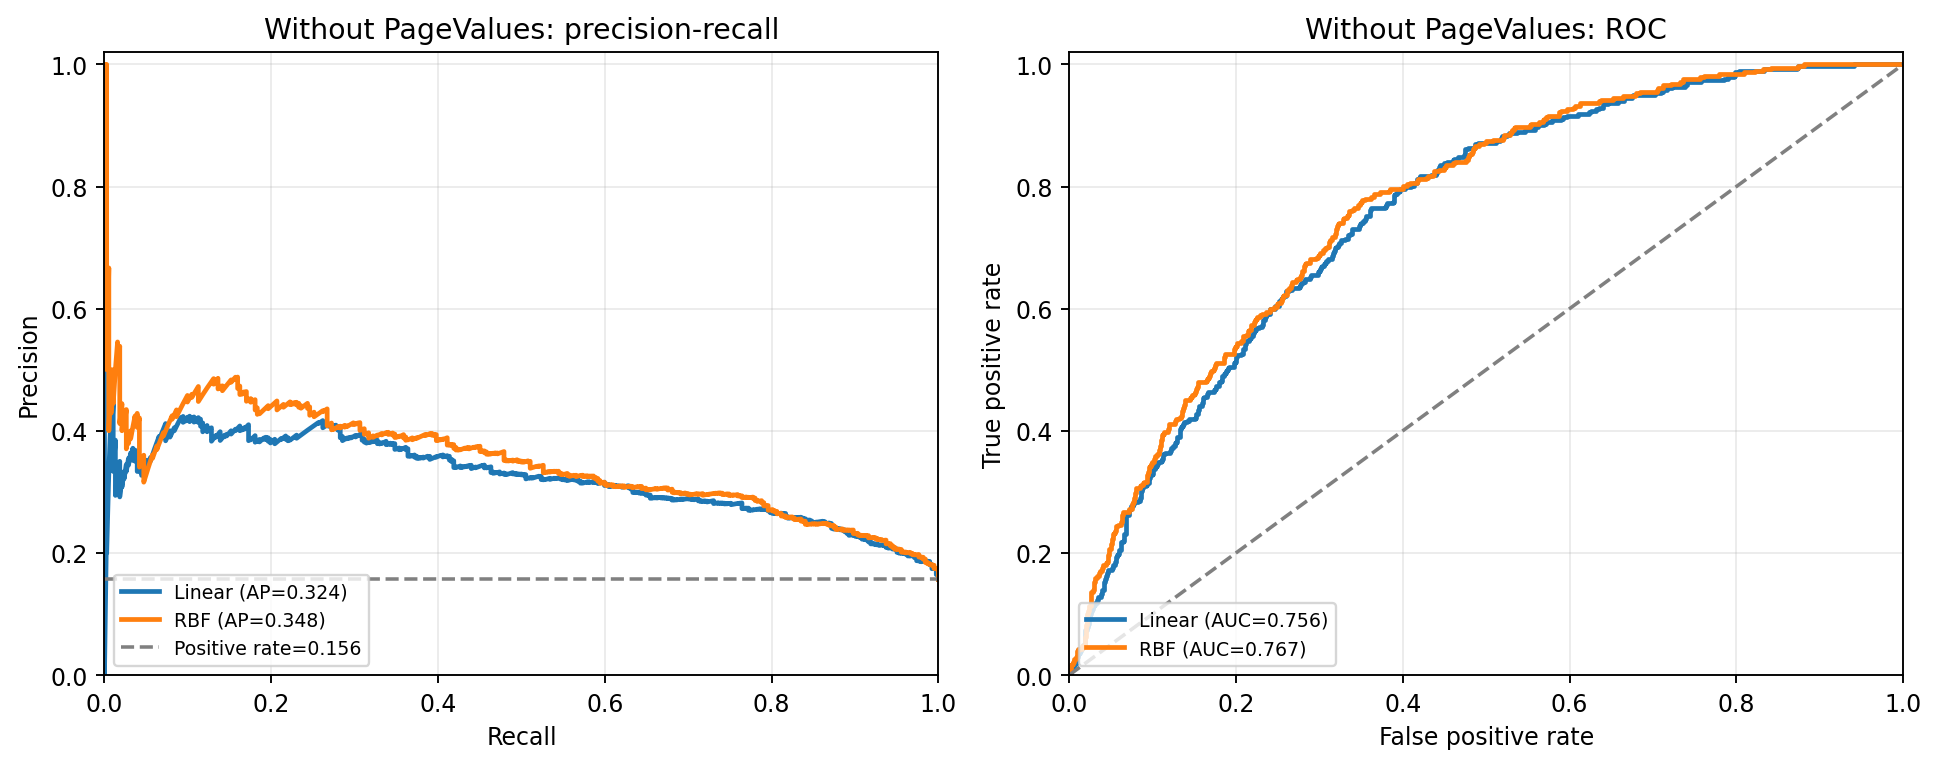

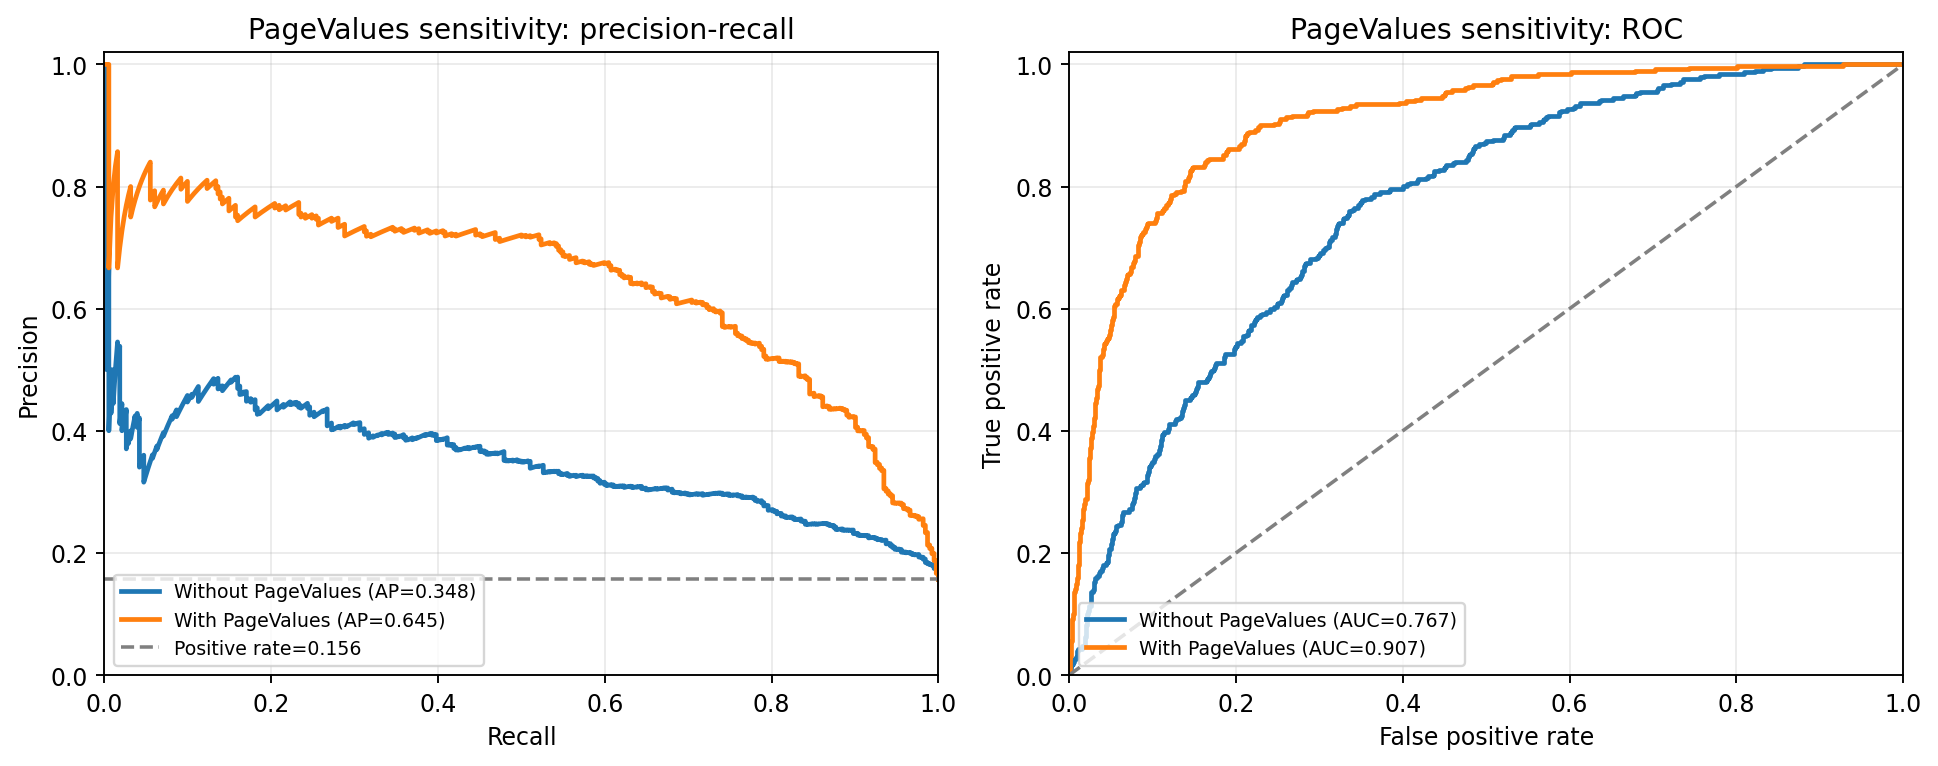

In [10]:
def ranking_figure(items, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
    for label, score in items:
        precision, recall, _ = precision_recall_curve(y_test, score)
        axes[0].plot(recall, precision, lw=2,
                     label=f'{label} (AP={average_precision_score(y_test, score):.3f})')
        fpr, tpr, _ = roc_curve(y_test, score)
        axes[1].plot(fpr, tpr, lw=2, label=f'{label} (AUC={roc_auc_score(y_test, score):.3f})')
    axes[0].axhline(y_test.mean(), ls='--', color='gray', label=f'Positive rate={y_test.mean():.3f}')
    axes[0].set(xlabel='Recall', ylabel='Precision', title=f'{title}: precision-recall', xlim=(0, 1), ylim=(0, 1.02))
    axes[1].plot([0, 1], [0, 1], ls='--', color='gray')
    axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title=f'{title}: ROC', xlim=(0, 1), ylim=(0, 1.02))
    for ax in axes:
        ax.legend(fontsize=8, loc='lower left')
    save_figure(fig, filename)

ranking_figure([(kernel, item['score']) for kernel, item in main_run['fitted'].items()],
               'Without PageValues', 'svm_main_ranking.png')
ranking_figure([(label, run['fitted'][run['winner']]['score']) for label, run in runs.items()],
               'PageValues sensitivity', 'svm_pagevalues_sensitivity.png')

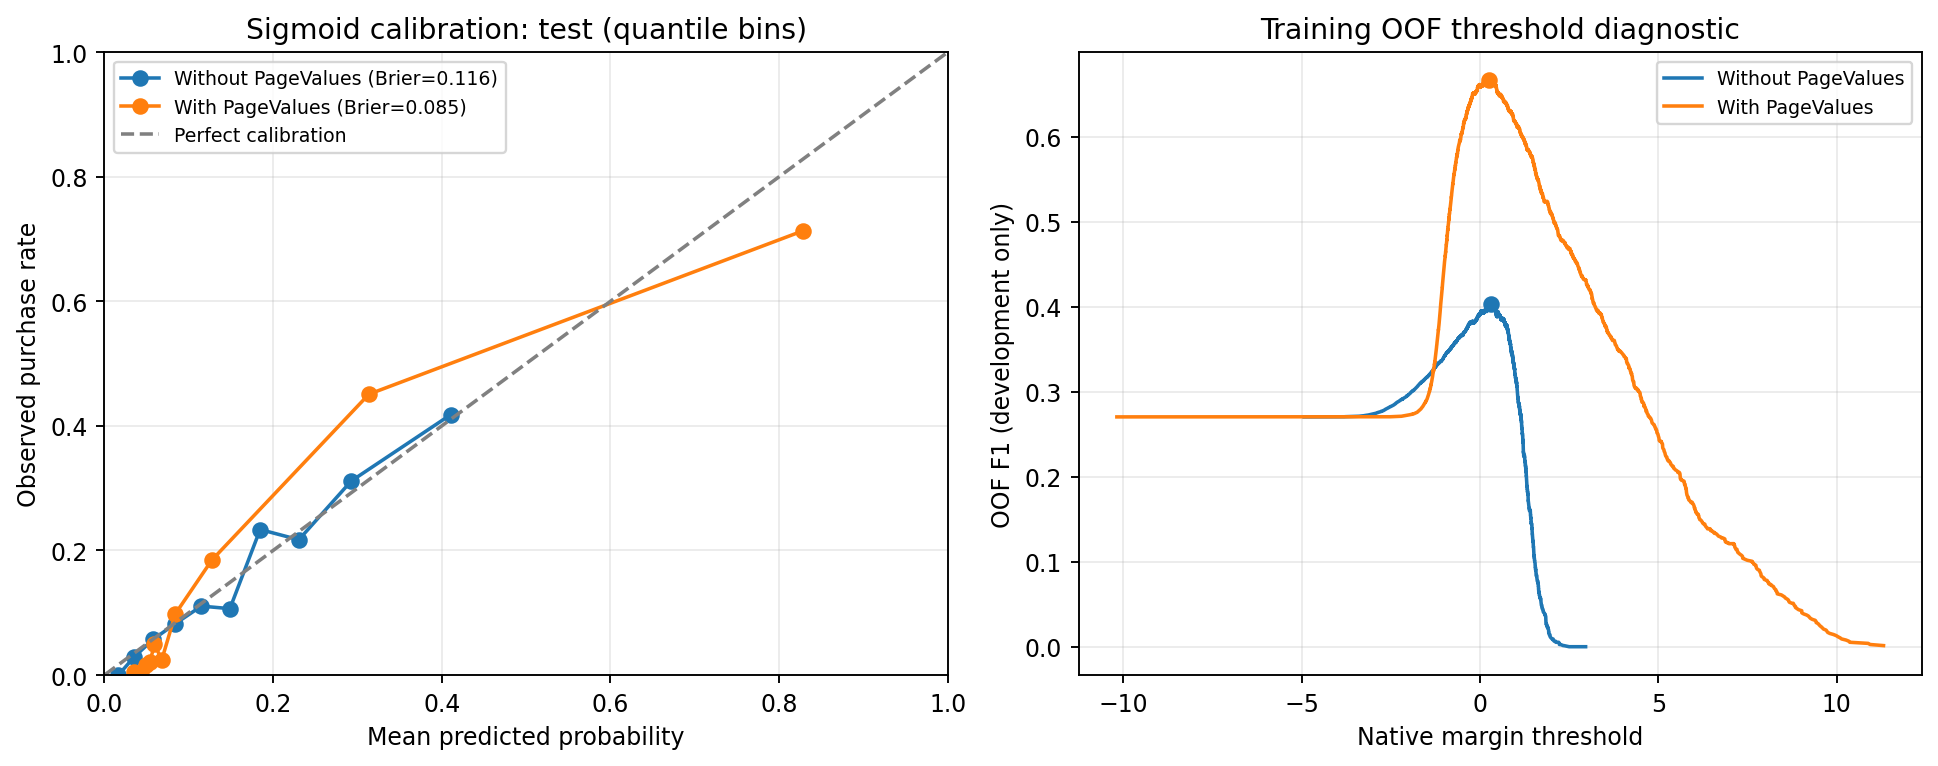

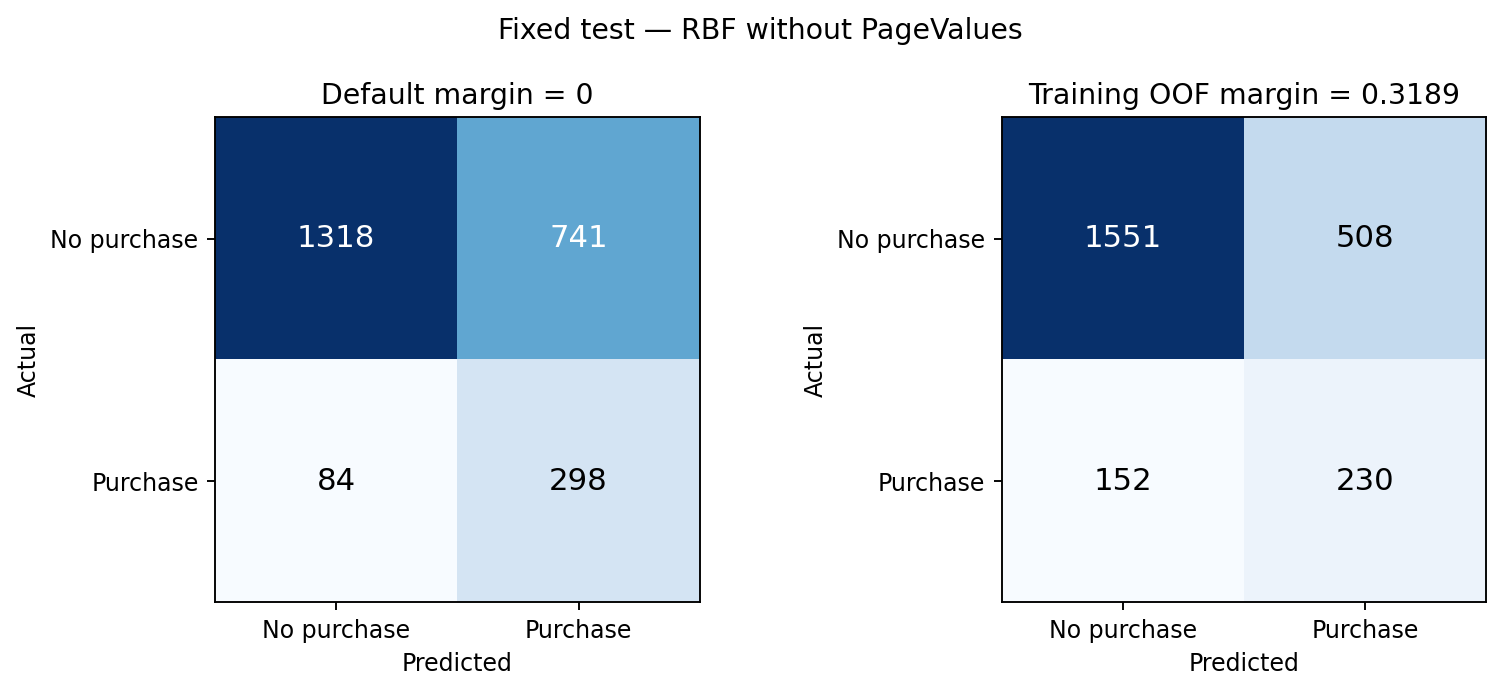

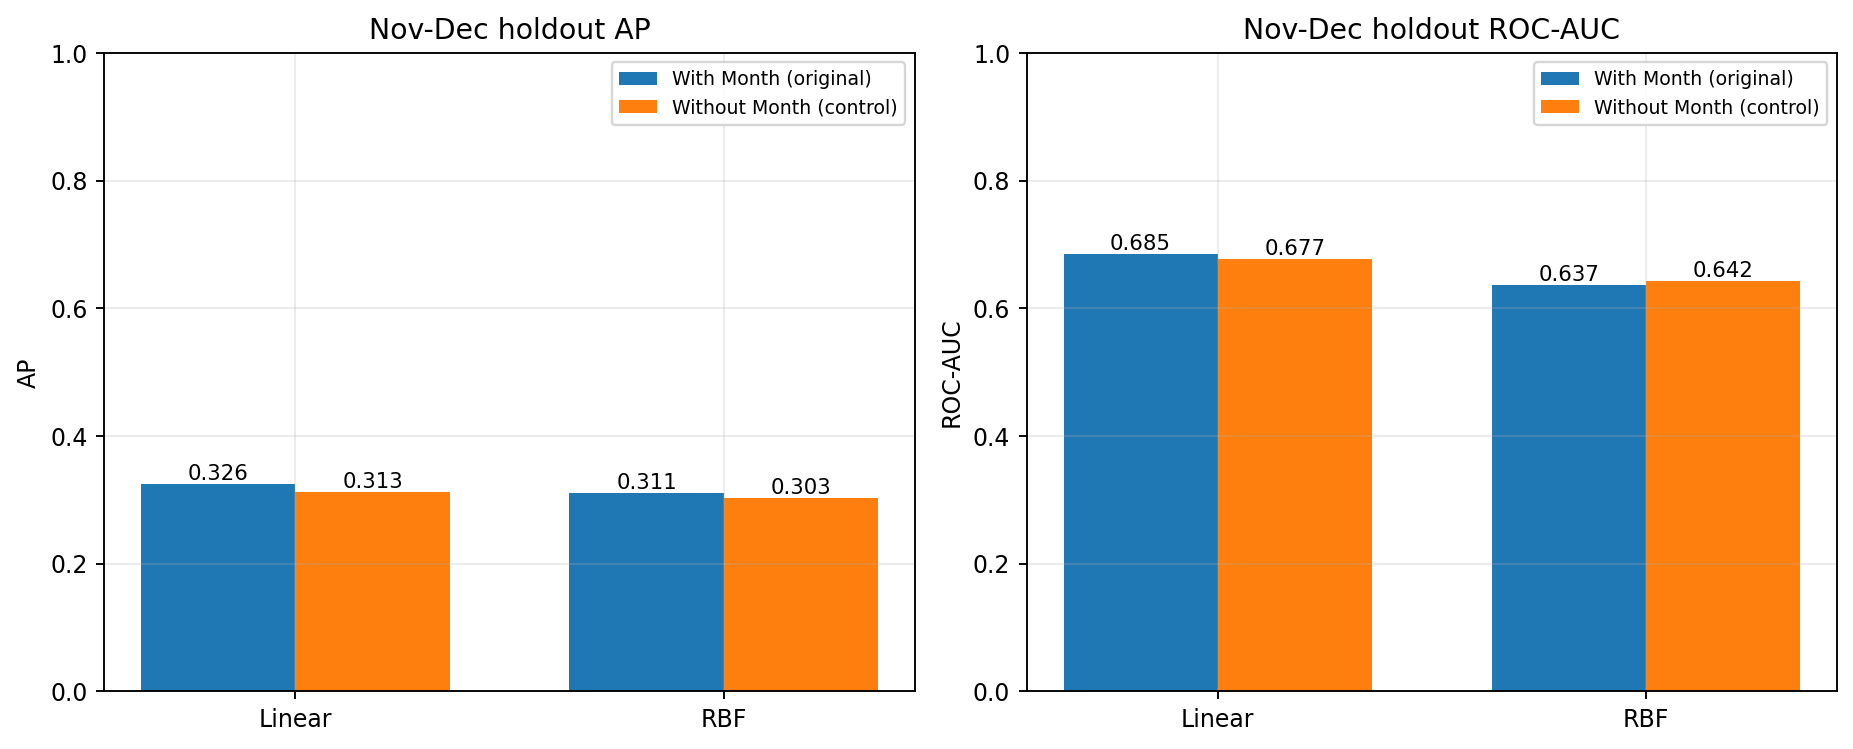

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for color, (label, run) in zip(['#1f77b4', '#ff7f0e'], runs.items()):
    frac_pos, mean_pred = calibration_curve(y_test, run['probability'], n_bins=10, strategy='quantile')
    brier = calibration_results.loc[calibration_results['Specification'].eq(label), 'Brier score'].iloc[0]
    axes[0].plot(mean_pred, frac_pos, marker='o', color=color, label=f'{label} (Brier={brier:.3f})')
    curve = run['threshold_curve']
    axes[1].plot(curve['native_margin_threshold'], curve['OOF F1'], color=color, label=label)
    axes[1].plot(run['threshold'], run['oof_development_f1'], 'o', color=color, markersize=6)
axes[0].plot([0, 1], [0, 1], ls='--', color='gray', label='Perfect calibration')
axes[0].set(title='Sigmoid calibration: test (quantile bins)', xlabel='Mean predicted probability',
            ylabel='Observed purchase rate', xlim=(0, 1), ylim=(0, 1))
axes[1].set(title='Training OOF threshold diagnostic', xlabel='Native margin threshold', ylabel='OOF F1 (development only)')
for ax in axes:
    ax.legend(fontsize=8)
save_figure(fig, 'svm_calibration_and_training_threshold.png')

selected = main_run['fitted'][main_run['winner']]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.1))
for ax, prediction, title in zip(
    axes,
    [selected['pred'], main_run['oof_threshold_test_prediction']],
    ['Default margin = 0', f"Training OOF margin = {main_run['threshold']:.4f}"],
):
    matrix = confusion_matrix(y_test, prediction, labels=[False, True])
    ax.imshow(matrix, cmap='Blues')
    for (row, column), value in np.ndenumerate(matrix):
        ax.text(column, row, str(value), ha='center', va='center',
                color='white' if value > matrix.max() / 2 else 'black', fontsize=13)
    ax.grid(False)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['No purchase', 'Purchase'],
           yticklabels=['No purchase', 'Purchase'], xlabel='Predicted', ylabel='Actual', title=title)
fig.suptitle(f"Fixed test — {main_run['winner']} without PageValues")
save_figure(fig, 'svm_main_confusion_matrices.png')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
x = np.arange(2)
for offset, (label, frame) in zip([-0.18, 0.18], [
    ('With Month (original)', temporal_results), ('Without Month (control)', month_excluded_results)
]):
    ordered = frame.set_index('Kernel').loc[['Linear', 'RBF']]
    for ax, metric in zip(axes, ['AP', 'ROC-AUC']):
        bars = ax.bar(x + offset, ordered[metric], 0.36, label=label)
        ax.bar_label(bars, fmt='%.3f', fontsize=9)
        ax.set(xticks=x, xticklabels=['Linear', 'RBF'], ylabel=metric,
               title=f'Nov-Dec holdout {metric}', ylim=(0, 1))
        ax.legend(fontsize=8, loc='upper right')
save_figure(fig, 'svm_month_holdout_comparison.png')

## 9. Linear-model interpretation

Retain the main specification's Linear SVM for directional interpretation even if RBF wins CV.
Coefficients describe a standardized/encoded decision margin, not odds ratios or causal effects.
One-hot encoding retains all categories; coefficient magnitudes also depend on regularization,
scaling and correlated features. Interpret this model's coefficients separately from the RBF model.

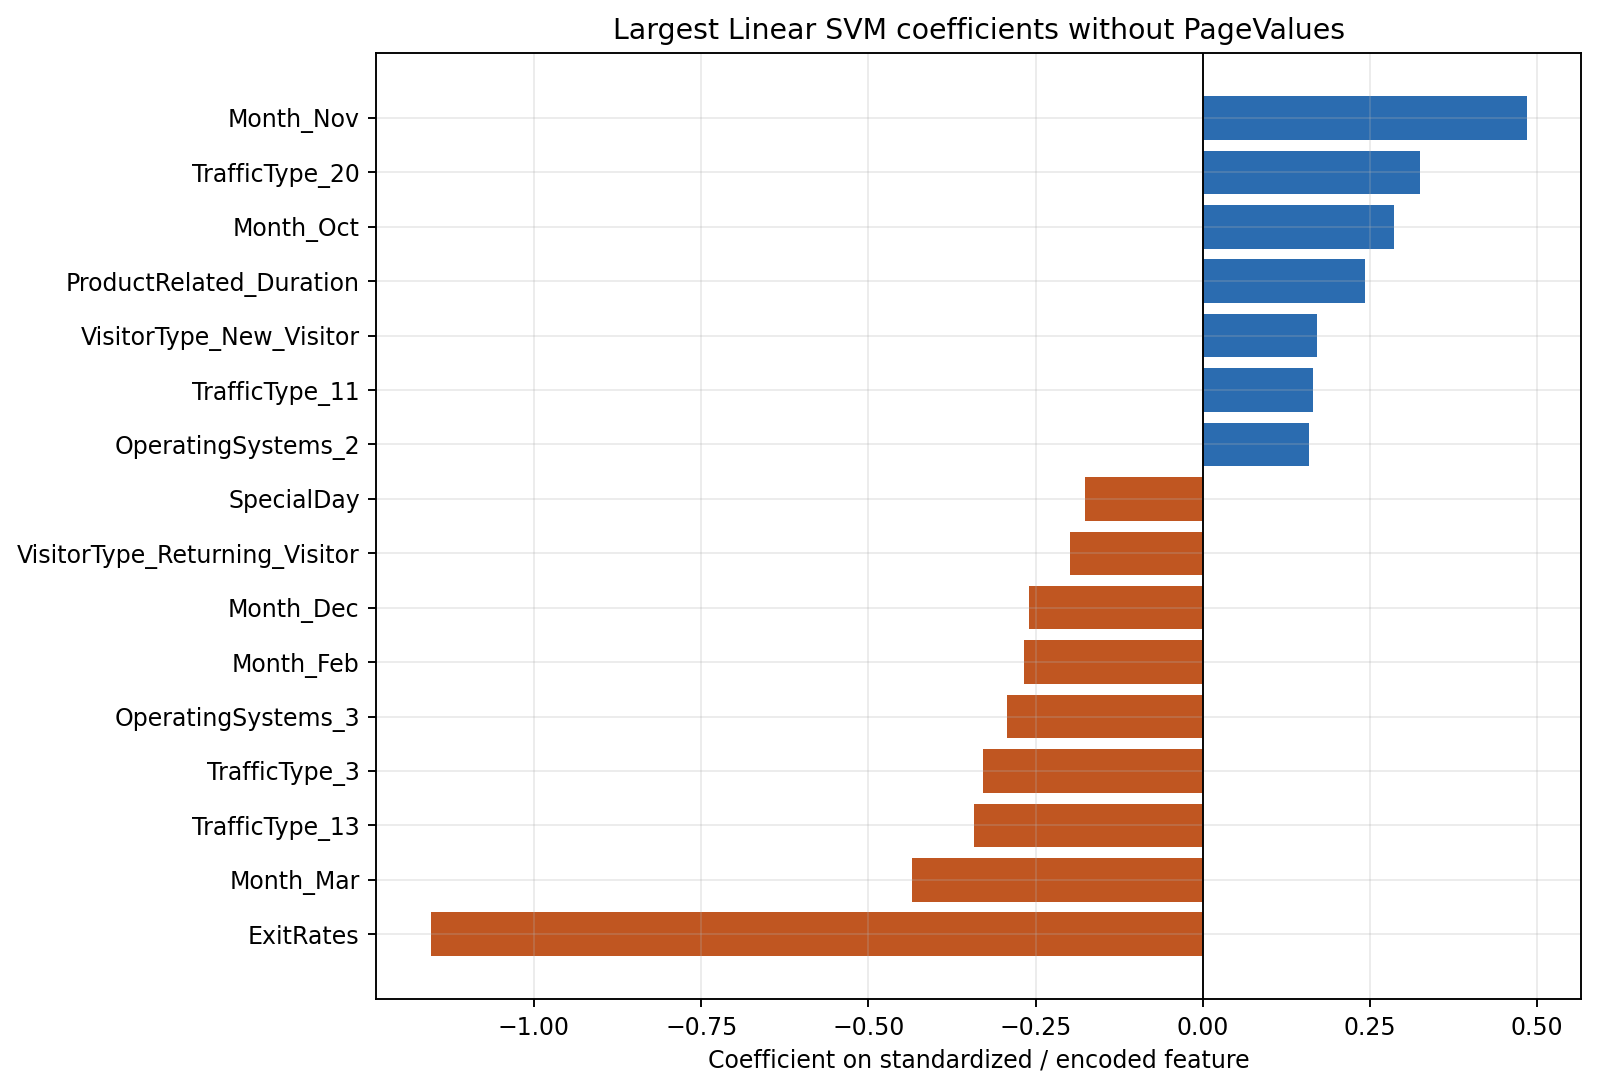

,Feature,Coefficient,Absolute coefficient
7,num__ExitRates,-1.153898,1.153898
16,cat__Month_Nov,0.484105,0.484105
14,cat__Month_Mar,-0.434761,0.434761
53,cat__TrafficType_13,-0.342205,0.342205
62,cat__TrafficType_3,-0.328332,0.328332
61,cat__TrafficType_20,0.323997,0.323997
21,cat__OperatingSystems_3,-0.292595,0.292595
17,cat__Month_Oct,0.285223,0.285223
11,cat__Month_Feb,-0.267883,0.267883
10,cat__Month_Dec,-0.260533,0.260533


In [12]:
linear_model = main_run['fitted']['Linear']['model']
feature_names = linear_model.named_steps['preprocess'].get_feature_names_out()
raw_coef = linear_model.named_steps['svc'].coef_
coef = raw_coef.toarray().ravel() if hasattr(raw_coef, 'toarray') else np.asarray(raw_coef).ravel()
coef_table = pd.DataFrame({'Feature': feature_names, 'Coefficient': coef})
coef_table['Absolute coefficient'] = coef_table['Coefficient'].abs()
coef_table = coef_table.sort_values('Absolute coefficient', ascending=False)
save_table(coef_table, 'svm_linear_coefficients.csv')
top = coef_table.head(16).sort_values('Coefficient')
names = top['Feature'].str.replace('num__', '', regex=False).str.replace('cat__', '', regex=False)
fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.barh(names, top['Coefficient'], color=np.where(top['Coefficient'] >= 0, '#2b6cb0', '#c05621'))
ax.axvline(0, color='black', lw=0.8)
ax.set(xlabel='Coefficient on standardized / encoded feature',
       title='Largest Linear SVM coefficients without PageValues')
save_figure(fig, 'svm_linear_coefficients.png', width=950)
display(coef_table.head(16))

## 10. Computed conclusion and completion checks

The summary below is generated from this run rather than copied from historical results.
Native-margin AP, default-margin classification, OOF-threshold classification and calibrated AP
remain separate. The month control adds evidence rather than replacing the original experiment.

Limitations: `PageValues` availability at prediction time remains unverified; results come from
one website/year; the month diagnostic mixes seasonality and distribution shift; reused training
folds can make CV/OOF development criteria optimistic; and probability calibration may drift.
A marketing intervention still needs a cost/capacity-based policy and an experiment to assess
its causal benefit. Do not choose a group-wide winning model from this SVM notebook alone.

In [13]:
main_result = oof_threshold_results.loc[oof_threshold_results['specification'].eq('Without PageValues')].iloc[0]
main_calibration = calibration_results.loc[calibration_results['Specification'].eq('Without PageValues')].iloc[0]
old_result = model_results.loc[
    model_results['Specification'].eq('Without PageValues') & model_results['Selected by CV']
].iloc[0]
conclusion = (
    f"**Main SVM selected by training CV:** {main_run['winner']}. "
    f"Fixed-test native-margin AP = {main_result['test_ap']:.4f}; "
    f"ROC-AUC = {main_result['test_roc_auc']:.4f}.\n\n"
    f"At the training OOF margin threshold {main_result['selected_threshold']:.6f}, "
    f"test precision = {main_result['test_precision']:.4f}, recall = {main_result['test_recall']:.4f}, "
    f"and F1 = {main_result['test_f1']:.4f}. "
    f"For comparison, the original default margin-zero recall = {old_result['Recall']:.4f} "
    f"and F1 = {old_result['F1']:.4f}.\n\n"
    f"**Separate sigmoid ensemble:** calibrated AP = {main_calibration['Calibrated AP']:.4f}, "
    f"Brier score = {main_calibration['Brier score']:.4f}, "
    f"ECE = {main_calibration['ECE (10 equal-width bins)']:.4f}. "
    "Probability scenarios are descriptive and do not select a policy."
)
for label, frame in [('With Month (original)', temporal_results),
                     ('Without Month (control)', month_excluded_results)]:
    row = frame.loc[frame['Selected by CV']].iloc[0]
    conclusion += (f"\n\n**{label}:** earlier-month CV selected {row['Kernel']}; "
                   f"Nov-Dec AP = {row['AP']:.4f}, ROC-AUC = {row['ROC-AUC']:.4f}. "
                   'This result does not replace the main fixed-split model.')
display(Markdown(conclusion))
(OUTPUT_DIR / 'computed_summary.md').write_text(conclusion + '\n', encoding='utf-8')

# Meaningful consistency checks on saved results; no test-derived selection.
for label, run in runs.items():
    selected = run['fitted'][run['winner']]
    if run['winner'] != run['cv_table'].loc[run['cv_table']['CV AP mean'].idxmax(), 'Kernel']:
        raise ValueError('Kernel selection is inconsistent with CV AP.')
    threshold_again, _, _ = choose_oof_f1_threshold(y_train, run['oof_margin'])
    if threshold_again != run['threshold']:
        raise ValueError('Threshold is inconsistent with training OOF scores.')
    row = oof_threshold_results.loc[oof_threshold_results['specification'].eq(label)].iloc[0]
    if not np.isclose(row['test_ap'], average_precision_score(y_test, selected['score'])):
        raise ValueError('Saved AP differs from native-margin AP.')
    probability_ap = calibration_results.loc[calibration_results['Specification'].eq(label), 'Calibrated AP'].iloc[0]
    if not np.isclose(probability_ap, average_precision_score(y_test, run['probability'])):
        raise ValueError('Saved calibrated AP differs from probability AP.')
if len(score_rows) != len(test) or not np.isfinite(score_rows.select_dtypes(include='number')).all().all():
    raise ValueError('Per-row test scores are incomplete or nonfinite.')
for path in [train_path, test_path]:
    if sha256(path) != data_hashes.loc[data_hashes['filename'].eq(path.name), 'sha256'].iloc[0]:
        raise ValueError('An input CSV changed during execution.')
for required in ['svm_oof_margin_threshold.csv', 'svm_test_scores.csv', 'svm_month_holdout_with_month.csv',
                 'svm_month_holdout_without_month.csv', 'svm_calibration_results.csv']:
    if not (OUTPUT_DIR / required).is_file():
        raise FileNotFoundError(f'Missing result: {required}')
write_json('run_status.json', {'status': 'complete', 'stages': stages,
                              'total_seconds': round(time.perf_counter() - started_at, 3)})
write_json('run_manifest.json', {
    'status': 'complete', 'run_id': RUN_ID, 'seed': SEED, 'cv': 'non-nested stratified five-fold',
    'parallel_backend': 'threading', 'n_jobs': N_JOBS,
    'scoring': 'average_precision', 'cv_sd_ddof': 0,
    'calibration': {'method': 'sigmoid', 'folds': 5, 'ensemble': True},
    'probability_scenarios': list(PROBABILITY_SCENARIOS),
    'threshold_rule': 'training OOF native-margin max F1; highest exact-tie threshold',
    'versions': versions, 'input_files': data_hashes.to_dict(orient='records'),
    'model_choices': locked_choices,
    'files': [{'filename': path.name, 'sha256': sha256(path)}
              for path in sorted(OUTPUT_DIR.iterdir()) if path.is_file() and path.name != 'run_manifest.json'],
})
print(f'Run complete. Tables, figures and manifest: {OUTPUT_DIR.as_posix()}')

**Main SVM selected by training CV:** RBF. Fixed-test native-margin AP = 0.3483; ROC-AUC = 0.7669.

At the training OOF margin threshold 0.318854, test precision = 0.3117, recall = 0.6021, and F1 = 0.4107. For comparison, the original default margin-zero recall = 0.7801 and F1 = 0.4194.

**Separate sigmoid ensemble:** calibrated AP = 0.3510, Brier score = 0.1161, ECE = 0.0083. Probability scenarios are descriptive and do not select a policy.

**With Month (original):** earlier-month CV selected RBF; Nov-Dec AP = 0.3107, ROC-AUC = 0.6371. This result does not replace the main fixed-split model.

**Without Month (control):** earlier-month CV selected RBF; Nov-Dec AP = 0.3030, ROC-AUC = 0.6425. This result does not replace the main fixed-split model.

Run complete. Tables, figures and manifest: results/member4_svm/20261024T141317_282061Z


## References

Sakar, C., & Kastro, Y. (2018). *Online Shoppers Purchasing Intention* [Dataset].
UCI Machine Learning Repository. https://doi.org/10.24432/C5F88Q

Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019).
Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and
LSTM recurrent neural networks. *Neural Computing and Applications, 31*(10), 6893–6908.
https://doi.org/10.1007/s00521-018-3523-0